## Logistic Regression in Practice: Credit Default Risk
---

### 1. Business Problem

A bank's **Credit Risk team** wants to know: **given what we know about an applicant, what is their probability of defaulting on a credit line, and which factors drive that risk?**

#### What does "default" mean?

In credit risk, **default** means a borrower fails to meet the agreed repayment terms. The most common operational definition and the one used in this dataset is:

> A client is marked as **default = 1** if they became **90+ days delinquent** on this credit line at any point during the **12 months** following approval. Otherwise, **default = 0**.

This 90 days past due convention is an industry standard (it's the same threshold used in Basel banking regulation), which is why we can treat it as a clean, already computed label rather than something we need to construct ourselves this time.

### 2. Data

`credito_default.csv` has **one row per client**, evaluated at the moment of credit approval. There is no time dimension here, every column describes the applicant as they looked when they applied.

#### Continuous variables

| Column | Description |
|---|---|
| `edad_cliente` | Client age |
| `ingreso_anual` | Annual income (MXN) |
| `monto_credito_solicitado` | Amount of credit requested (MXN) |
| `tasa_utilizacion_credito` | % of available credit currently in use across all the client's accounts |
| `razon_deuda_ingreso` | Debt to income ratio (%), total monthly debt payments over monthly income |
| `antiguedad_crediticia_anios` | Years since the client's oldest credit account was opened |
| `num_cuentas_credito` | Number of open credit accounts |
| `num_consultas_recientes` | Number of credit inquiries in the last 12 months |

#### Categorical variables

| Column | Categories | Reference category |
|---|---|---|
| `tipo_vivienda` | Propia / Rentada / Hipotecada | **Propia** |
| `proposito_credito` | Gastos Personales / Consolidación de Deuda / Automotriz / Mejoras del Hogar | **Gastos Personales** |
| `nivel_educativo` | Preparatoria / Licenciatura / Posgrado | **Preparatoria** |

#### Target

| Column | Description |
|---|---|
| `default` | 1 = defaulted within 12 months, 0 = did not. **Already computed**. |

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, classification_report, roc_curve, auc,
                             accuracy_score, precision_score, recall_score, f1_score)

pd.set_option('display.max_columns', None)
plt.rcParams['figure.figsize'] = (8, 5)

df = pd.read_csv('credito_default.csv')
print(df.shape)
df.head()

(1200, 13)


,id_cliente,edad_cliente,ingreso_anual,monto_credito_solicitado,tasa_utilizacion_credito,razon_deuda_ingreso,antiguedad_crediticia_anios,num_cuentas_credito,num_consultas_recientes,tipo_vivienda,proposito_credito,nivel_educativo,default
0,CR-00001,21,133182.0,99755.0,42.3,10.3,13.1,3,0,Propia,Gastos Personales,Preparatoria,0
1,CR-00002,54,349597.0,70442.0,21.3,31.8,16.2,7,1,Rentada,Gastos Personales,Preparatoria,0
2,CR-00003,50,250336.0,30681.0,45.0,27.5,5.8,2,3,Propia,Gastos Personales,Posgrado,0
3,CR-00004,23,60000.0,44325.0,51.7,52.5,2.7,4,2,Hipotecada,Mejoras del Hogar,Licenciatura,1
4,CR-00005,65,295733.0,159279.0,41.1,8.3,6.9,1,3,Propia,Gastos Personales,Preparatoria,0


### 3. Review Data Quality

We're told this dataset is already clean, let's verify that claim rather than take it on faith, exactly the kind of check we'd run before trusting any dataset.

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 13 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   id_cliente                   1200 non-null   object 
 1   edad_cliente                 1200 non-null   int64  
 2   ingreso_anual                1200 non-null   float64
 3   monto_credito_solicitado     1200 non-null   float64
 4   tasa_utilizacion_credito     1200 non-null   float64
 5   razon_deuda_ingreso          1200 non-null   float64
 6   antiguedad_crediticia_anios  1200 non-null   float64
 7   num_cuentas_credito          1200 non-null   int64  
 8   num_consultas_recientes      1200 non-null   int64  
 9   tipo_vivienda                1200 non-null   object 
 10  proposito_credito            1200 non-null   object 
 11  nivel_educativo              1200 non-null   object 
 12  default                      1200 non-null   int64  
dtypes: float64(5), int

In [3]:
print('Missing values per column:')
print(df.isna().sum())
print()
print('Duplicate id_cliente:', df['id_cliente'].duplicated().sum())

Missing values per column:
id_cliente                     0
edad_cliente                   0
ingreso_anual                  0
monto_credito_solicitado       0
tasa_utilizacion_credito       0
razon_deuda_ingreso            0
antiguedad_crediticia_anios    0
num_cuentas_credito            0
num_consultas_recientes        0
tipo_vivienda                  0
proposito_credito              0
nivel_educativo                0
default                        0
dtype: int64

Duplicate id_cliente: 0


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
edad_cliente,1200.0,44.735000,14.195869,21.0,32.750,44.0,57.00,69.0
ingreso_anual,1200.0,180125.905833,87833.097540,60000.0,113282.500,162939.0,231470.00,593713.0
monto_credito_solicitado,1200.0,75247.583333,42858.667064,15000.0,44328.000,66879.0,96869.25,297096.0
tasa_utilizacion_credito,1200.0,35.908583,19.363169,1.5,20.200,34.0,49.85,95.7
razon_deuda_ingreso,1200.0,30.848833,16.573135,0.1,17.775,29.2,42.00,83.9
antiguedad_crediticia_anios,1200.0,8.115917,5.137499,0.5,4.500,7.1,10.70,34.0
num_cuentas_credito,1200.0,3.993333,1.905601,1.0,3.000,4.0,5.00,14.0
num_consultas_recientes,1200.0,1.285000,1.167581,0.0,0.000,1.0,2.00,6.0
default,1200.0,0.265000,0.441517,0.0,0.000,0.0,1.00,1.0


**Confirmed clean:** no missing values, no duplicate client IDs, and every numeric range looks sensible (ages between 21-69, utilization and debt ratios bounded between 0-100%, no negative amounts). Categorical values are worth a quick check too:

In [5]:
print(sorted(df['tipo_vivienda'].unique()))
print(sorted(df['proposito_credito'].unique()))
print(sorted(df['nivel_educativo'].unique()))

['Hipotecada', 'Propia', 'Rentada']
['Automotriz', 'Consolidación de Deuda', 'Gastos Personales', 'Mejoras del Hogar']
['Licenciatura', 'Posgrado', 'Preparatoria']


No inconsistent spellings or stray categories, we can go straight to analysis without a cleaning step this time.

### 4. Exploratory Analysis | Understanding `default`

#### 4.1 Overall default rate

Overall default rate: 26.5%


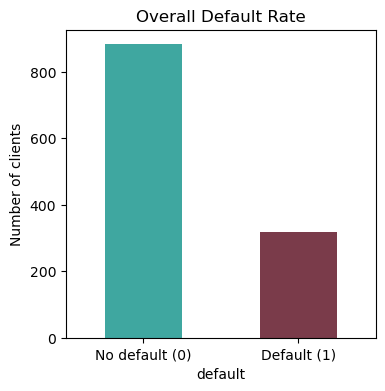

In [6]:
default_rate = df['default'].mean()
print(f'Overall default rate: {default_rate*100:.1f}%')

fig, ax = plt.subplots(figsize=(4, 4))
df['default'].value_counts().sort_index().plot(kind='bar', ax=ax, color=['#3FA7A0', '#7A3B4A'])
ax.set_xticklabels(['No default (0)', 'Default (1)'], rotation=0)
ax.set_ylabel('Number of clients')
ax.set_title('Overall Default Rate')
plt.show()

**Interpretation:** 

About 26.5% of clients in this portfolio defaulted within 12 months. That's a meaningful minority, not a rare event, but it's also far from a 50/50 split, which its important  to keep in mind once we get to modeling.

#### 4.2 Default rate vs. numeric predictors

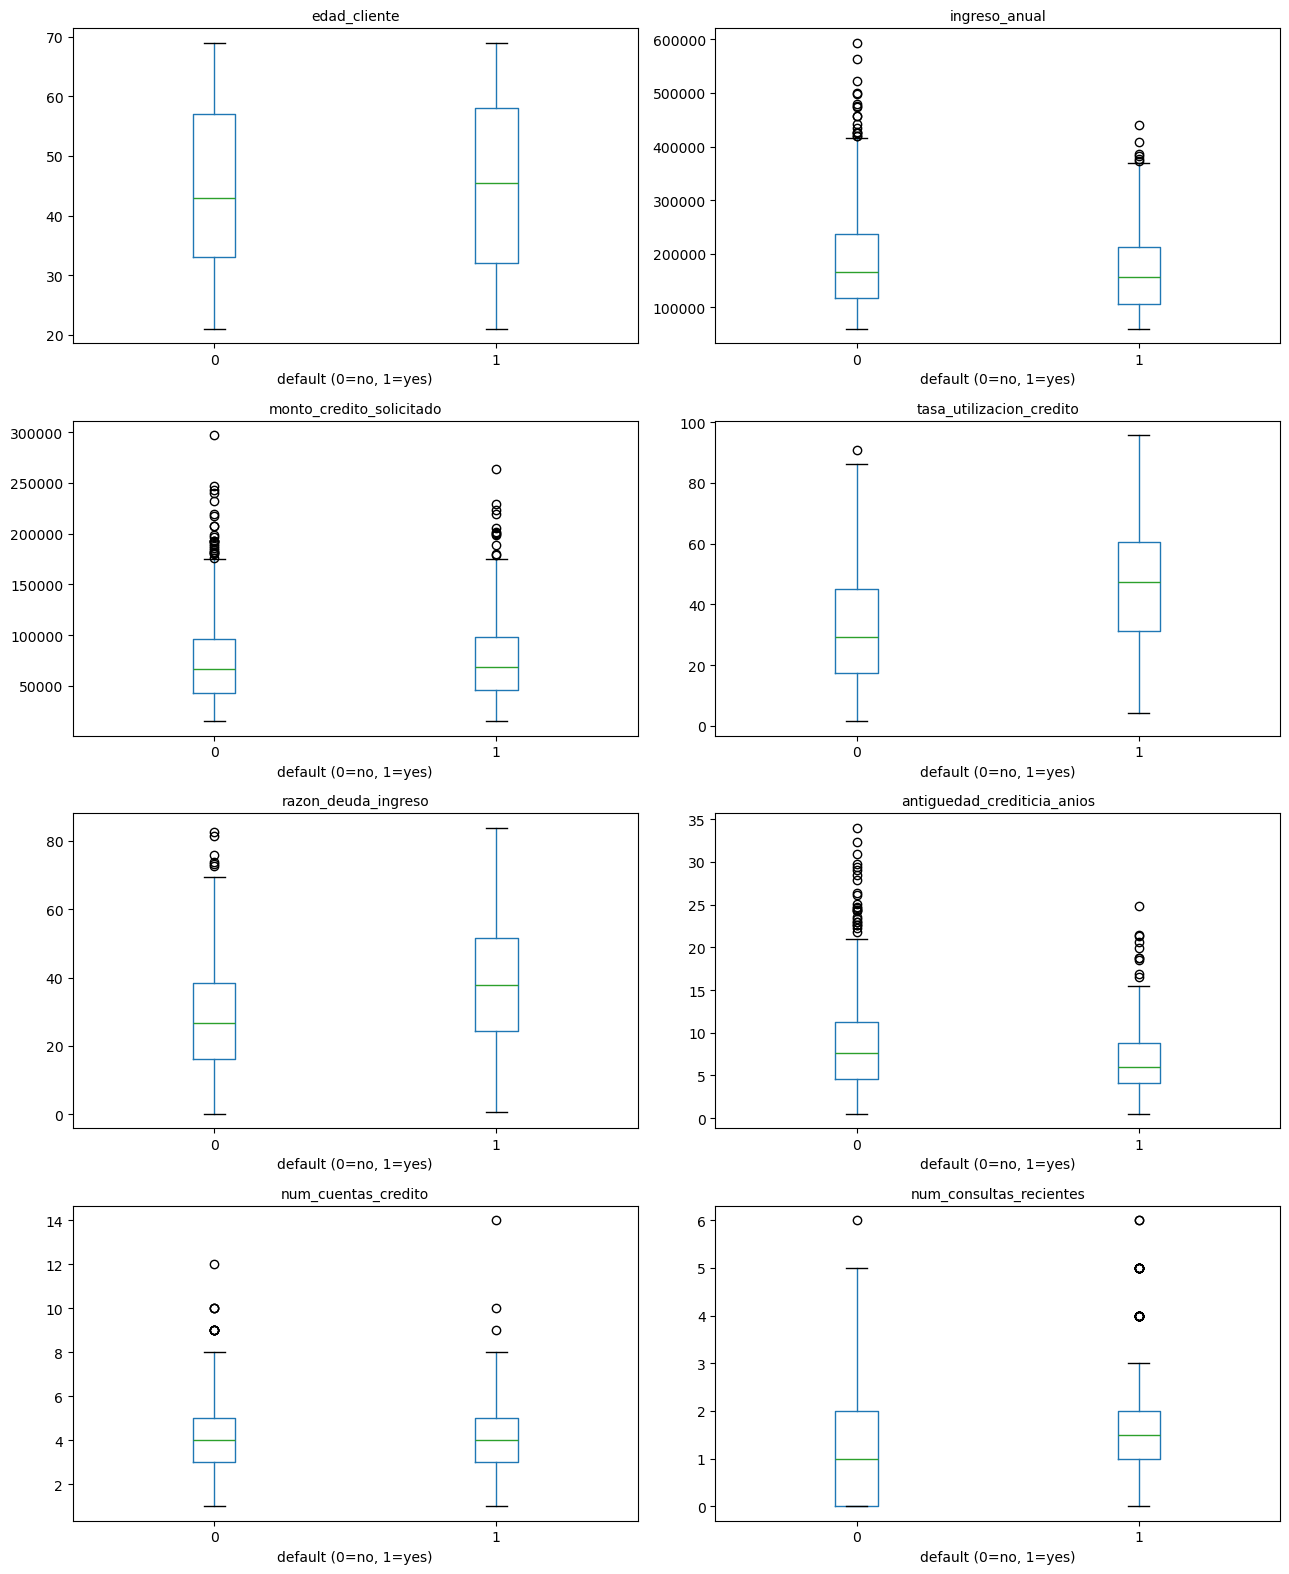

In [14]:
numeric_cols = ['edad_cliente', 'ingreso_anual', 'monto_credito_solicitado',
                'tasa_utilizacion_credito', 'razon_deuda_ingreso',
                'antiguedad_crediticia_anios', 'num_cuentas_credito', 'num_consultas_recientes']

fig, axes = plt.subplots(4, 2, figsize=(13,16))
axes = axes.flatten()
for i, col in enumerate(numeric_cols):
    df.boxplot(column=col, by='default', ax=axes[i], grid=False)
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel('default (0=no, 1=yes)')
plt.suptitle('')
plt.tight_layout()
plt.show()

In [15]:
df.groupby('default')[numeric_cols].mean().round(2).T

default,0,1
edad_cliente,44.66,44.96
ingreso_anual,184491.68,168017.07
monto_credito_solicitado,74360.15,77708.94
tasa_utilizacion_credito,32.16,46.31
razon_deuda_ingreso,28.29,37.96
antiguedad_crediticia_anios,8.56,6.90
num_cuentas_credito,3.94,4.13
num_consultas_recientes,1.16,1.64


**Interpreting each variable:**

- **`tasa_utilizacion_credito`**: the clearest gap of all, clients who default average 46% utilization vs. 32% for those who don't. Someone already using most of their available credit has less room to absorb a shock, and utilization is a classic leading indicator of distress.
- **`razon_deuda_ingreso`**: a similarly large gap (38% vs. 28%) — makes intuitive sense: a client already committing more of their income to debt payments has less cushion.
- **`antiguedad_crediticia_anios`**: defaulters average nearly 2 fewer years of credit history (6.9 vs. 8.6), a shorter track record gives the bank less evidence the client can manage credit reliably.
- **`num_consultas_recientes`**: defaulters show more recent credit inquiries (1.64 vs. 1.16), often a sign someone is actively seeking new credit, sometimes because they're already stretched thin elsewhere.
- **`edad_cliente`**, **`ingreso_anual`**, **`monto_credito_solicitado`**, **`num_cuentas_credito`**: all show only small differences between groups. These may turn out to matter little once we control for the stronger variables above — worth keeping an eye on once we fit the actual model.

#### 4.3 Default rate vs. categorical predictors

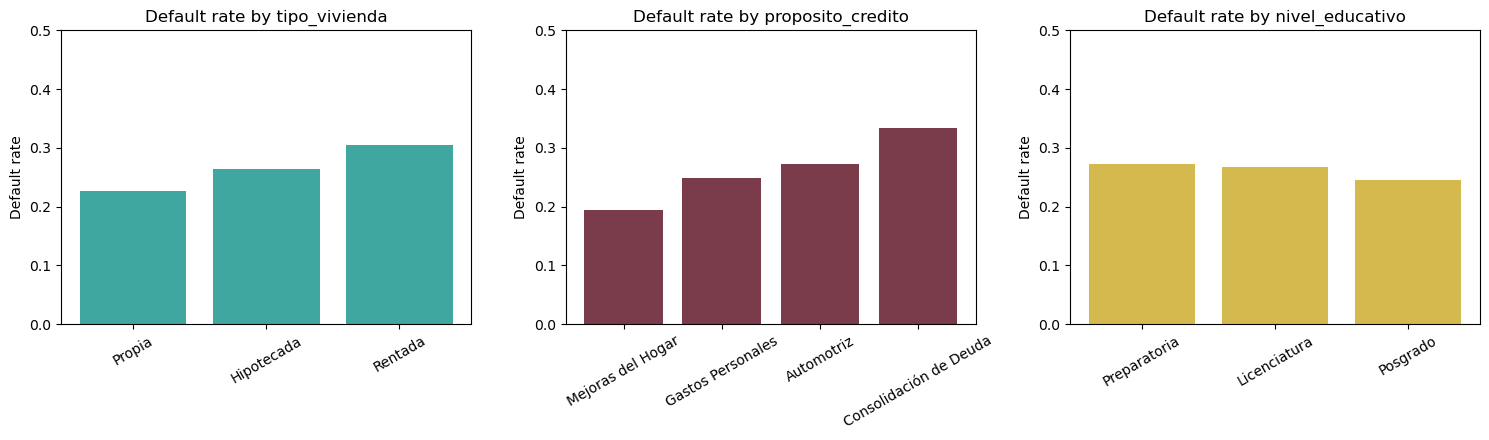

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

vivienda_order = ['Propia', 'Hipotecada', 'Rentada']
vivienda_rate = df.groupby('tipo_vivienda')['default'].mean().reindex(vivienda_order)
axes[0].bar(vivienda_rate.index, vivienda_rate.values, color='#3FA7A0')
axes[0].set_ylabel('Default rate'); axes[0].set_ylim(0, 0.5)
axes[0].set_title('Default rate by tipo_vivienda')
axes[0].tick_params(axis='x', rotation=30)

prop_order = ['Mejoras del Hogar', 'Gastos Personales', 'Automotriz', 'Consolidación de Deuda']
prop_rate = df.groupby('proposito_credito')['default'].mean().reindex(prop_order)
axes[1].bar(prop_rate.index, prop_rate.values, color='#7A3B4A')
axes[1].set_ylabel('Default rate'); axes[1].set_ylim(0, 0.5)
axes[1].set_title('Default rate by proposito_credito')
axes[1].tick_params(axis='x', rotation=30)

educ_order = ['Preparatoria', 'Licenciatura', 'Posgrado']
educ_rate = df.groupby('nivel_educativo')['default'].mean().reindex(educ_order)
axes[2].bar(educ_rate.index, educ_rate.values, color='#D4B94E')
axes[2].set_ylabel('Default rate'); axes[2].set_ylim(0, 0.5)
axes[2].set_title('Default rate by nivel_educativo')
axes[2].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

**Interpreting each chart:**

- **`tipo_vivienda`**: Homeowners (`Propia`) default least (22.7%), renters (`Rentada`) default most (30.4%), with mortgage-holders in between (26.3%). This makes sense: owning a home outright is itself a signal of accumulated financial stability.
- **`proposito_credito`**: the clearest categorical story, clients borrowing to **consolidate existing debt** default most often (33.4%), while those borrowing for **home improvements** default least (19.4%). This is intuitive: someone consolidating debt is, by definition, already carrying debt they're struggling with; someone investing in their home is often in a stronger financial position to begin with.
- **`nivel_educativo`**: essentially flat (24.5%-27.2% across all three levels), education level doesn't seem to separate defaulters from non defaulters much in this portfolio.

### 5. Checking Class Balance

default
0    0.735
1    0.265
Name: proportion, dtype: float64


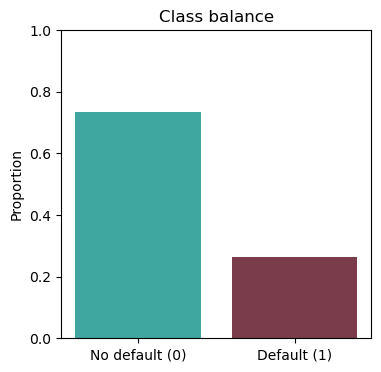

In [18]:
balance = df['default'].value_counts(normalize=True).sort_index()
print(balance.round(3))

fig, ax = plt.subplots(figsize=(4, 4))
ax.bar(['No default (0)', 'Default (1)'], balance.values, color=['#3FA7A0', '#7A3B4A'])
ax.set_ylabel('Proportion'); ax.set_ylim(0, 1)
ax.set_title('Class balance')
plt.show()

At roughly **73.5% / 26.5%**, this is a real, noticeable class imbalance, common in credit risk, where most clients in any portfolio are, by design, clients the bank already approved and who are performing fine.

#### Why imbalance is a problem

- **Accuracy becomes a misleading headline number.** A model that predicts "no default" for every single client would already be right about 73.5% of the time, a high accuracy score that hides the fact it never once catches a real defaulter, which is precisely the group a risk team cares about most.

- **The model itself has less to learn from.** With fewer default examples to learn from, maximum likelihood estimation has a weaker signal for what separates a defaulter from a non-defaulter, and coefficient estimates for the minority class become less stable.

- **The default 0.5 classification threshold stops making sense.** A model can assign a defaulting client only a 35% predicted probability, genuinely elevated relative to the 26.5% base rate, and still get classified as "no default" under a naive 0.5 cutoff.

#### Common techniques to correct it

| Technique | Idea |
|---|---|
| **Oversampling** (e.g., SMOTE) | Synthesize additional minority-class (default) examples so the training set is more balanced |
| **Undersampling** | Randomly drop majority-class (non default) examples to match the minority class size |
| **Class weights** | Penalize misclassifying the minority class more heavily during fitting (`class_weight='balanced'` in scikit-learn) |
| **Threshold adjustment** | Lower the 0.5 cutoff for flagging "default" — trading some false alarms for catching more real defaulters |
| **Threshold-independent metrics** | Report ROC-AUC (Section 7) rather than relying on accuracy alone, since AUC doesn't depend on picking a cutoff |

We won't apply any of these here, our imbalance (73/27) is real but moderate, and the metrics we'll use (sensitivity, specificity, AUC) are already chosen specifically to stay meaningful under imbalance. These techniques become more important as imbalance gets more extreme (e.g., 1-5% default rates, common in some retail portfolios).

### 6. Train/Test Split

In [19]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['default'])
print(f'Train: {len(train_df)}   Test: {len(test_df)}')
print('Train default rate:', train_df['default'].mean().round(3))
print('Test default rate: ', test_df['default'].mean().round(3))

Train: 960   Test: 240
Train default rate: 0.265
Test default rate:  0.267


### 7. Model 1 | Single Variable

From the EDA, `tasa_utilizacion_credito` showed the clearest gap between groups — the classic first question a risk analyst would ask: **does credit utilization alone predict default?**

In [75]:
X1_train = sm.add_constant(train_df[['tasa_utilizacion_credito']])
y_train = train_df['default']

model1 = sm.GLM(y_train, X1_train, family=sm.families.Binomial()).fit()
print(model1.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                default   No. Observations:                  960
Model:                            GLM   Df Residuals:                      958
Model Family:                Binomial   Df Model:                            1
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -501.98
Date:                Wed, 30 Sep 2026   Deviance:                       1004.0
Time:                        21:57:12   Pearson chi2:                     952.
No. Iterations:                     4   Pseudo R-squ. (CS):             0.1040
Covariance Type:            nonrobust                                         
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                   

#### 7.1 Testing the Coefficient's Significance

- $H₀ : β_{tasa_utilizacion} = 0$  (utilization has no effect on default risk)
- $H₁ : β_{tasa_utilizacion} ≠ 0 $ (utilization does affect default risk)

**Significance level:** $\alpha = 0.05$

**Decision rule:**
- If $p-value < \alpha$ **Reject $H_0$**: variable has a statistically significant effect on default risk.
- If $p-value\geq \alpha$ **Fail to reject $H_0$**: there is not enough evidence that the variable affects default risk.

In [76]:
model1.pvalues['tasa_utilizacion_credito']

4.644438684223528e-22

**Interpretation:** There is very strong statistical evidence that credit utilization rate has a significant effect on default risk.

#### 7.2 Interpreting the Coefficient | Log-Odds and Odds

**Log-odds scale (the raw coefficient):** for each additional percentage point of credit utilization, the log-odds of default increase by β.

**Odds scale (exponentiating β):** a multiplicative effect on the odds of default themselves — easier to explain to a credit committee than a log-odds number.

In [51]:
coef = model1.params['tasa_utilizacion_credito']
coef

0.04025045801410919

In [52]:
np.exp(coef)

1.0410714862393038

In [53]:
odds_ratio = np.exp(coef)

print('LOG-ODDS SCALE:')
print(f'  beta = {coef:.4f}')
print(f'  -> each extra point of utilization adds {coef:.4f} to the log-odds of default')
print()
print('ODDS SCALE:')
print(f'  odds ratio = exp(beta) = {odds_ratio:.4f}')
print(f'  -> each extra point of utilization multiplies the odds of default by {odds_ratio:.4f}')
print(f'  -> for +20 points of utilization: {odds_ratio**20:.3f}x the odds of default')

LOG-ODDS SCALE:
  beta = 0.0403
  -> each extra point of utilization adds 0.0403 to the log-odds of default

ODDS SCALE:
  odds ratio = exp(beta) = 1.0411
  -> each extra point of utilization multiplies the odds of default by 1.0411
  -> for +20 points of utilization: 2.237x the odds of default


A 4.4% increase in the odds of default per point of utilization sounds modest, but utilization ranges widely across clients, the compounding effect over 20-30 points is substantial, as the last line above shows.

#### 7.3 Evaluating Model 1 | Confusion Matrix and Evaluation Metrics

In [54]:
X1_test = sm.add_constant(test_df[['tasa_utilizacion_credito']])
y_test = test_df['default']

proba1 = model1.predict(X1_test)
pred1 = (proba1 >= 0.5).astype(int)

cm1 = confusion_matrix(y_test, pred1)
print('Confusion matrix (rows = actual, columns = predicted):')
print(pd.DataFrame(cm1, index=['Actual: No default (0)', 'Actual: Default (1)'],
                    columns=['Predicted: No default (0)', 'Predicted: Default (1)']))

Confusion matrix (rows = actual, columns = predicted):
                        Predicted: No default (0)  Predicted: Default (1)
Actual: No default (0)                        166                      10
Actual: Default (1)                            55                       9


In [58]:
tn, fp, fn, tp = cm1.ravel()

sensitivity1 = recall_score(y_test, pred1)               # TP / (TP+FN)
specificity1 = tn / (tn + fp)                             # TN / (TN+FP)
precison1 = precision_score(y_test, pred1)                     # TP / (TP+FP)
npv1 = tn / (tn + fn)                                     # TN / (TN+FN)
accuracy1 = accuracy_score(y_test, pred1)
f1_1 = f1_score(y_test, pred1)
pseudo_r2_1 =  1 - model1.deviance / model1.null_deviance

metrics1 = pd.Series({
    'TP': tp, 'TN': tn, 'FP': fp, 'FN': fn,
    'sensitivity (recall)': sensitivity1,
    'specificity': specificity1,
    'precision': precison1,
    'NPV': npv1,
    'accuracy': accuracy1,
    'F1-score': f1_1,
    'pseudo R2': pseudo_r2_1,
})
metrics1.round(3)

TP                        9.000
TN                      166.000
FP                       10.000
FN                       55.000
sensitivity (recall)      0.141
specificity               0.943
precision                 0.474
NPV                       0.751
accuracy                  0.729
F1-score                  0.217
pseudo R2                 0.095
dtype: float64

**Interpreting each metric** (remember: `default = 1` is our positive class):

- **TP = 15, TN = 170, FP = 13, FN = 42.** Of the 57 clients who actually defaulted in the test set, this model only correctly flagged 15 of them.
- **Sensitivity (recall) = 0.141**: of clients who truly default, we only catch 14.1% of them. That's a real weakness for a risk model, most actual defaulters are slipping through as "predicted fine."
- **Specificity = 0.943**: of clients who truly don't default, we correctly clear 93% of them, the model is very good at confirming who's safe.
- **Precision = 0.474**: when the model does flag someone as a default risk, it's right about 47% of the timem a coin-flip-plus, not yet strong enough to act on alone.
- **NPV = 0.75**: when the model clears someone as "no default," it's right 75% of the time, reasonably trustworthy, but not perfect: 1 in 5 "cleared" clients still defaults.
- **Accuracy = 0.729**: 73% of all predictions are correct, but given the 73.5% base rate of non-default, this is barely better than always guessing "no default," which is exactly why accuracy alone is a poor headline metric here.
- **F1-score = 0.217**: the harmonic mean of precision and sensitivity, and it's low mainly because sensitivity (recall) is so weak, F1 punishes exactly the kind of lopsided performance we see here.
- **Pseudo-R² ≈ 0.0.95**: modest, as expected for a single variable model, there's clearly more going on than utilization alone can capture.

#### 7.4 ROC Curve and AUC

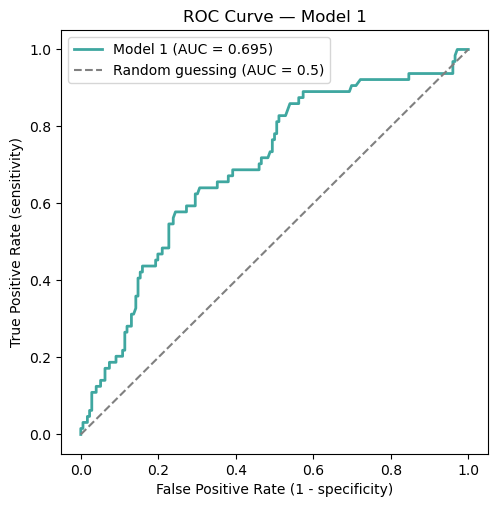

In [59]:
fpr1, tpr1, thresholds1 = roc_curve(y_test, proba1)
auc1 = auc(fpr1, tpr1)

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot(fpr1, tpr1, color='#3FA7A0', linewidth=2, label=f'Model 1 (AUC = {auc1:.3f})')
ax.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random guessing (AUC = 0.5)')
ax.set_xlabel('False Positive Rate (1 - specificity)')
ax.set_ylabel('True Positive Rate (sensitivity)')
ax.set_title('ROC Curve — Model 1')
ax.legend()
plt.show()

**Interpreting the ROC curve and AUC:** the ROC curve traces sensitivity vs. (1-specificity) across **every possible threshold**, not just 0.5, this is exactly why AUC is a good threshold independent complement to the accuracy/sensitivity/specificity numbers above, which only describe one specific cutoff.

**AUC = 0.695** has a clean interpretation: if we randomly pick one client who defaulted and one who didn't, there's a 64% chance the model assigns a higher predicted probability of default to the one who actually defaulted. That's better than a coin flip (0.5), but far from the near perfect separation a AUC close to 1.0 would represent, consistent with the pseudo-R², and a reminder that with just one variable, this model has real, but limited, discriminating power.

#### 8. Model 2 | All variables Model

One hot encode the categoricals with explicit reference categories: `tipo_vivienda` reference **Propia**; `proposito_credito` reference **Gastos Personales**; `nivel_educativo` reference **Preparatoria**.

In [85]:
def encode(d):
    out = d.copy()
    
    # Fix the category order so the reference category is first (and gets dropped)
    out["tipo_vivienda"] = pd.Categorical(out["tipo_vivienda"], categories=["Propia", "Rentada", "Hipotecada"])
    out["proposito_credito"] = pd.Categorical(out["proposito_credito"], categories=["Gastos Personales", "Consolidación de Deuda", "Automotriz", "Mejoras del Hogar"])
    out["nivel_educativo"] = pd.Categorical(out["nivel_educativo"], categories=["Preparatoria", "Licenciatura", "Posgrado"])
    
    dummies = pd.get_dummies(out[["tipo_vivienda", "proposito_credito", "nivel_educativo"]], drop_first=True, dtype=float)
    dummies.columns = dummies.columns.str.replace(" ", "_")  # keep column names friendly

    out = out.drop(columns=["tipo_vivienda", "proposito_credito", "nivel_educativo"])  # <- quita las originales
    return pd.concat([out, dummies], axis=1)

train_enc = encode(train_df)
test_enc = encode(test_df)

feature_cols = ['edad_cliente', 'ingreso_anual',
       'monto_credito_solicitado', 'tasa_utilizacion_credito',
       'razon_deuda_ingreso', 'antiguedad_crediticia_anios',
       'num_cuentas_credito', 'num_consultas_recientes',
       'tipo_vivienda_Rentada', 'tipo_vivienda_Hipotecada',
       'proposito_credito_Consolidación_de_Deuda',
       'proposito_credito_Automotriz', 'proposito_credito_Mejoras_del_Hogar',
       'nivel_educativo_Licenciatura', 'nivel_educativo_Posgrado']

X2_train = sm.add_constant(train_enc[feature_cols])
X2_test = sm.add_constant(test_enc[feature_cols])

model2 = sm.GLM(y_train, X2_train, family=sm.families.Binomial()).fit()
print(model2.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                default   No. Observations:                  960
Model:                            GLM   Df Residuals:                      944
Model Family:                Binomial   Df Model:                           15
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -421.37
Date:                Wed, 30 Sep 2026   Deviance:                       842.74
Time:                        22:06:26   Pearson chi2:                     929.
No. Iterations:                     5   Pseudo R-squ. (CS):             0.2425
Covariance Type:            nonrobust                                         
                                               coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------

#### 8.1 Testing Every Coefficient

- $H₀ : β = 0$  (utilization has no effect on default risk)
- $H₁ : β ≠ 0 $ (utilization does affect default risk)

**Significance level:** $\alpha = 0.05$

**Decision rule:**
- If $p-value < \alpha$ **Reject $H_0$**: variable has a statistically significant effect on default risk.
- If $p-value\geq \alpha$ **Fail to reject $H_0$**: there is not enough evidence that the variable affects default risk.

Let's build the decision explicitly rather than scanning the table by eye.

In [82]:
hypothesis_tests = pd.DataFrame({
    'coef (log-odds)': model2.params,
    'odds_ratio': np.exp(model2.params),
    'p_value': model2.pvalues
})
hypothesis_tests['reject_H0_at_5pct'] = hypothesis_tests['p_value'] < 0.05
hypothesis_tests.round(4)

,coef (log-odds),odds_ratio,p_value,reject_H0_at_5pct
const,-4.3809,0.0125,0.0000,True
edad_cliente,0.0031,1.0031,0.6156,False
ingreso_anual,-0.0000,1.0000,0.0037,True
monto_credito_solicitado,0.0000,1.0000,0.2142,False
tasa_utilizacion_credito,0.0466,1.0477,0.0000,True
razon_deuda_ingreso,0.0450,1.0461,0.0000,True
antiguedad_crediticia_anios,-0.0945,0.9098,0.0000,True
num_cuentas_credito,0.0550,1.0566,0.2222,False
num_consultas_recientes,0.3613,1.4352,0.0000,True
tipo_vivienda_Rentada,0.5621,1.7544,0.0047,True


In [86]:
hypothesis_tests[hypothesis_tests['reject_H0_at_5pct']== True].round(4)


,coef (log-odds),odds_ratio,p_value,reject_H0_at_5pct
const,-4.3809,0.0125,0.0000,True
ingreso_anual,-0.0000,1.0000,0.0037,True
tasa_utilizacion_credito,0.0466,1.0477,0.0000,True
razon_deuda_ingreso,0.0450,1.0461,0.0000,True
antiguedad_crediticia_anios,-0.0945,0.9098,0.0000,True
num_consultas_recientes,0.3613,1.4352,0.0000,True
tipo_vivienda_Rentada,0.5621,1.7544,0.0047,True


#### 8.2 Interpreting the Full Model

**Statistically significant (p < 0.05):**
- `tasa_utilizacion_credito` and `razon_deuda_ingreso`: both remain strongly significant, positive, and are the two largest drivers of default risk even after controlling for everything else.
- `antiguedad_crediticia_anios` - negative and significant: more years of credit history lowers default risk, holding other factors fixed.
- `num_consultas_recientes` - positive and significant: more recent credit inquiries raises default risk independently of utilization and debt ratio.
- `ingreso_anual` - negative and significant: higher income lowers default risk, holding everything else fixed. The coefficient looks tiny (income is measured in raw pesos, so one extra peso barely moves the needle), but it's a genuine, independent effect once compounded over realistic income differences.
- **`tipo_vivienda_Rentada`** (vs. `Propia` reference) - **our significant categorical variable.** Even after accounting for financial behavior (utilization, debt ratio, credit history, income), renting a home still carries independent default risk beyond what those financial variables already capture. Odds ratio ≈ 1.75 — a renter has roughly 75% higher odds of default than a homeowner, all else equal.

**Not statistically significant** (despite `tipo_vivienda_Hipotecada` and education levels looking somewhat different in the raw EDA, and `proposito_credito_Consolidación_de_Deuda` landing close but short at p ≈ 0.08): `edad_cliente`, `monto_credito_solicitado`, `num_cuentas_credito`, `tipo_vivienda_Hipotecada`, `proposito_credito_Automotriz`, `proposito_credito_Mejoras_del_Hogar`, `nivel_educativo_Licenciatura`, `nivel_educativo_Posgrado`.

#### 8.3 Interpreting the Significant Categorical Variable | Log-Odds and Odds

**`tasa_utilizacion_credito`** (coef = 0.0466, p < 0.0001)
- **Log-odds:** each additional point of credit utilization increases the log-odds of default by 0.0466.
- **Odds:** exp(0.0466) ≈ **1.048** → each additional point multiplies the odds of default by 1.048 (+4.8%). For +20 points: 1.048²⁰ ≈ 2.52x the odds.

**`razon_deuda_ingreso`** (coef = 0.0450, p < 0.0001)
- **Log-odds:** each additional point in the debt-to-income ratio increases the log-odds of default by 0.0450.
- **Odds:** exp(0.0450) ≈ **1.046** → each additional point multiplies the odds of default by 1.046 (+4.6%) — almost identical in size to credit utilization's effect.

**`antiguedad_crediticia_anios`** (coef = −0.0945, p < 0.0001)
- **Log-odds:** each additional year of credit history *lowers* the log-odds of default by 0.0945.
- **Odds:** exp(−0.0945) ≈ **0.910** → each additional year multiplies the odds of default by 0.910 (−9%). For +5 years: 0.910⁵ ≈ 0.624x the odds — roughly a 38% reduction in the odds of default.

**`num_consultas_recientes`** (coef = 0.3613, p < 0.0001)
- **Log-odds:** each additional credit inquiry in the last 12 months increases the log-odds of default by 0.3613.
- **Odds:** exp(0.3613) ≈ **1.435** → each additional inquiry multiplies the odds of default by 1.435 (+43.5%), the single largest per-unit effect in the model, though most clients only have 0-3 inquiries, so its total impact across the portfolio is moderate.

**`ingreso_anual`** (coef ≈ −0.0000, p = 0.0037)
- **Log-odds:** the coefficient looks tiny because income is measured in raw pesos, a single extra peso barely moves anything.
- **Odds:** exp(coef) rounds to essentially 1.000 at this scale, which is why we scale it up to a decision-relevant range instead: 
  - for every extra **$10,000 MXN** of annual income, the odds of default multiply by **0.970** (a ~3% reduction). 
  - Scaled further to a **$100,000 MXN** income gap, a realistic difference between clients, the cumulative effect is 0.970¹⁰ ≈ **0.74**, a **~26% reduction** in the odds of default.
  - A coefficient that looks negligible at face value can still represent a real, meaningful effect once scaled to how much the variable actually varies across clients.

**`tipo_vivienda_Rentada`** (coef = 0.5621, p = 0.0047) — vs. `Propia` reference
- **Log-odds:** renting (vs. owning outright) increases the log-odds of default by 0.5621.
- **Odds:** exp(0.5621) ≈ **1.754** → a renter has roughly **75% higher odds** of default than a homeowner, holding everything else — including financial behavior — fixed.

#### 8.4 Evaluating Model 2 | Confusion Matrix and Core Metrics

In [100]:
proba2 = model2.predict(X2_test)
pred2 = (proba2 >= 0.5).astype(int)

cm2 = confusion_matrix(y_test, pred2)
print('Confusion matrix (rows = actual, columns = predicted):')
print(pd.DataFrame(cm2, index=['Actual: No default (0)', 'Actual: Default (1)'],
                    columns=['Predicted: No default (0)', 'Predicted: Default (1)']))

Confusion matrix (rows = actual, columns = predicted):
                        Predicted: No default (0)  Predicted: Default (1)
Actual: No default (0)                        161                      15
Actual: Default (1)                            40                      24


In [103]:
tn2, fp2, fn2, tp2 = cm2.ravel()

sensitivity2 = recall_score(y_test, pred2)               # TP / (TP+FN)
specificity2 = tn2 / (tn2 + fp2)                             # TN / (TN+FP)
precison2 = precision_score(y_test, pred2)                     # TP / (TP+FP)
npv2 = tn2 / (tn2 + fn2)                                     # TN / (TN+FN)
accuracy2 = accuracy_score(y_test, pred2)
f1_2 = f1_score(y_test, pred2)
pseudo_r2_2 =  1 - model2.deviance / model2.null_deviance

metrics2 = pd.Series({
    'TP': tp2, 'TN': tn2, 'FP': fp2, 'FN': fn2,
    'sensitivity (recall)': sensitivity2,
    'specificity': specificity2,
    'precision': precison2,
    'NPV': npv2,
    'accuracy': accuracy2,
    'F1-score': f1_2,
    'pseudo R2': pseudo_r2_2,
})

comparison_full = pd.DataFrame({
    'Model 1 (utilization only)': metrics1,
    'Model 2 (full model)': metrics2,
}).round(3)
comparison_full

,Model 1 (utilization only),Model 2 (full model)
TP,9.000,24.000
TN,166.000,161.000
FP,10.000,15.000
FN,55.000,40.000
sensitivity (recall),0.141,0.375
specificity,0.943,0.915
precision,0.474,0.615
NPV,0.751,0.801
accuracy,0.729,0.771
F1-score,0.217,0.466


**Reading the comparison, metric by metric:**

- **Recall** jumps from 0.141 to 0.375, a large, genuine improvement in catching actual defaulters, though the full model still misses nearly 2 out of 3 (62.5%) at the default 0.5 threshold.
- **Specificity actually drops slightly** (0.943 → 0.915) - Model 2 trades a small amount of its ability to correctly clear safe clients in exchange for catching more defaulters. This is a real, if modest, trade-off, not a clean win on every front.
- **Precision improves** (0.474 → 0.615) - when Model 2 flags someone as a default risk, it's right notably more often.
- **NPV improves slightly** (0.751 → 0.801) - clearing decisions are a bit more trustworthy too.
- **Accuracy rises** (0.729 → 0.771), and **F1 more than doubles** (0.217 → 0.466) - F1 responds strongly here because sensitivity, the weakest link in Model 1, improved so much.
- **Pseudo-R² more than doubles** (0.095 → 0.240) - the richer feature set explains substantially more of what separates defaulters from non-defaulters.

**The honest takeaway:** Model 2 is better overall, but not uniformly better - it gives up a small amount of specificity to gain a large amount of sensitivity. For a bank where missing a defaulter (FN) is typically far more costly than one extra unnecessary manual review (FP), this is almost certainly the right trade to make - but it's worth stating explicitly rather than claiming Model 2 "wins on every metric," which it doesn't quite do.

#### 8.5 ROC Curve and AUC — Model 2

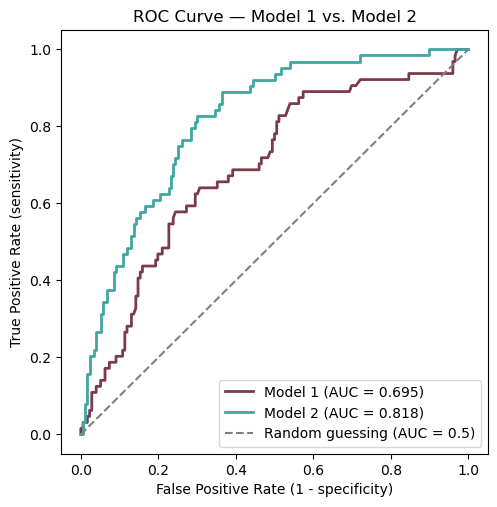

In [104]:
fpr2, tpr2, thresholds2 = roc_curve(y_test, proba2)
auc2 = auc(fpr2, tpr2)

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot(fpr1, tpr1, color='#7A3B4A', linewidth=2, label=f'Model 1 (AUC = {auc1:.3f})')
ax.plot(fpr2, tpr2, color='#3FA7A0', linewidth=2, label=f'Model 2 (AUC = {auc2:.3f})')
ax.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random guessing (AUC = 0.5)')
ax.set_xlabel('False Positive Rate (1 - specificity)')
ax.set_ylabel('True Positive Rate (sensitivity)')
ax.set_title('ROC Curve — Model 1 vs. Model 2')
ax.legend()
plt.show()

**Interpreting the comparison:** Model 2's curve sits well above Model 1's across virtually the entire range of thresholds, and **AUC jumps from 0.69 to 0.81**.

### 9. Recommendations

#### 9.1 Technical Recommendations (modeling craft only — no repeated findings below)

1. **Drop low-value variables** (`edad_cliente`, `monto_credito_solicitado`, `num_cuentas_credito`, `nivel_educativo`) from a production model, they add little once stronger predictors are included.
2. **Keep `Consolidación_de_Deuda` on watch**, not dismissed, just short of significance (p ≈ 0.08), worth re-testing as data grows.
3. **Always scale a coefficient to a meaningful range before judging its size**, a lesson from `ingreso_anual`, whose raw coefficient looked negligible but wasn't.
4. **Tune the classification threshold using the ROC curve**, not the 0.5 default - at 0.5, Model 2 catches only 37.5% of defaulters.

#### 9.2 Business Recommendations (substantive findings only — no modeling mechanics above)

1. **Utilization and debt-to-income ratio are the strongest signals**- worth tracking continuously, not just at approval.
2. **Income is a real protective factor at realistic scale** - a $100,000 MXN gap corresponds to ~26% lower default odds.
3. **Renters carry ~75% higher default odds than homeowners**, even controlling for financial behavior - worth a closer look on borderline cases.
4. **Recent inquiries and short credit history add cheap, independent signal** - good candidates for automated pre-screening.
5. **The cost trade-off between missing a defaulter and over-flagging a safe client is a business call**, not a modeling detail - the committee, not the model, should set that line.